In [1]:
import numpy as np
from lib.dvr2d import *
from lib.utils import *
from lib.vqe import DVR_VQE
from lib.pot_gen import get_pot

import matplotlib.pyplot as plt
from matplotlib import rc

log_file = 'results/log.txt'

cmap = plt.get_cmap('tab10')
plt.rcParams["figure.figsize"] = (5,5)
plt.rcParams["font.size"] = 12
plt.rcParams["figure.dpi"] = 300
rc('text', usetex=True)
rc('font',**{'family':'serif','serif':['Computer Modern']})
%load_ext autoreload

In [2]:
mol_params = mgnh_params
pot_file = 'mgnh.txt'

dvr_options = {
    'type': 'jacobi',
    'N_R': 20, 
    'N_theta': 4,
    'l': 1,
    'K_max': 0,
    'r_min': 3,
    'r_max': 6, 
    'trunc': 0,
    'J': 0
}

vqe_options = {
    'optimizers': ['L_BFGS_B.8000'],
    # 'optimizers': ['COBYLA.100'],
    # 'repeats': 1, 
    'repeats': 5, 
    'beta': [1000 for i in range(10)],
    'seed': 42
}

ansatz_options = {
    'type': 'twolocal',
    'entanglement': 'opt',
    'gates': [9, 4, 1],
    'reps': 1,
}


In [3]:
import qiskit
import qiskit_algorithms
import qiskit_aer

print(qiskit.__version__)
print(qiskit_algorithms.__version__)
print(qiskit_aer.__version__)

2.2.3
0.4.0
0.17.2


In [4]:
pot = get_pot(pot_file, take_cos=False)
dvr_vqe = DVR_VQE(mol_params, pot, log_dir='results/tests/')
# opt_params = dvr_vqe.get_dvr_vqe(dvr_options, ansatz_options, vqe_options, excited_states=True)

In [5]:
ansatz_options2 = {
    'type': 'twolocal',
    'entanglement': 'opt',
    'gates': [39, 4, 21, 8, 13, 19, 7, 34, 30, 14],
    'reps': 4,
}

# opt_params2 = dvr_vqe.get_dvr_vqe(dvr_options, ansatz_options2, vqe_options, excited_states=True)

In [6]:
with np.load('results/excited_states/mgnh_twolocal_opt_1/opt_params.npz', allow_pickle=True) as data:
    opt_params = data['opt_params']

with np.load('results/excited_states/mgnh_twolocal_opt_4/opt_params.npz', allow_pickle=True) as data:
    opt_params2 = data['opt_params']
# opt_params = []
# energies = []
# with np.load('results/excited_states/mgnh_twolocal_opt_1(1)/vqe.npz', allow_pickle=True) as data:
#     opt_params.append(*data['params'])
#     energies.append(data['energies'])

# for i in range(1, 11):
#     with np.load(f'results/excited_states/mgnh_twolocal_opt_1(1)/vqe_excited{i}.npz', allow_pickle=True) as data:
#         opt_params.append(*data['params'])
#         energies.append(data['energies'])

# energies = np.array(energies).flatten()
# opt_params = np.array(opt_params)
# print(opt_params.shape)

# opt_params2 = []
# energies2 = []
# with np.load('results/excited_states/mgnh_twolocal_opt_4/vqe.npz', allow_pickle=True) as data:
#     opt_params2.append(*data['params'])
#     energies2.append(data['energies'])

# for i in range(1, 11):
#     with np.load(f'results/excited_states/mgnh_twolocal_opt_4/vqe_excited{i}.npz', allow_pickle=True) as data:
#         opt_params2.append(*data['params'])
#         energies2.append(data['energies'])

# energies2 = np.array(energies2).flatten()
# opt_params2 = np.array(opt_params2)
# print(opt_params2.shape)

In [7]:
ansatz = dvr_vqe.get_ansatz(ansatz_options, 5)
ansatz2 = dvr_vqe.get_ansatz(ansatz_options2, 5)
print(ansatz)
print(ansatz2)

     ┌─────────────┐ ░            ░ ┌─────────────┐
q_0: ┤ Ry($x_{0}$) ├─░───■────────░─┤ Ry($x_{5}$) ├
     ├─────────────┤ ░   │        ░ ├─────────────┤
q_1: ┤ Ry($x_{1}$) ├─░───┼────■───░─┤ Ry($x_{6}$) ├
     ├─────────────┤ ░ ┌─┴─┐┌─┴─┐ ░ ├─────────────┤
q_2: ┤ Ry($x_{2}$) ├─░─┤ X ├┤ X ├─░─┤ Ry($x_{7}$) ├
     ├─────────────┤ ░ └───┘└───┘ ░ ├─────────────┤
q_3: ┤ Ry($x_{3}$) ├─░───■────────░─┤ Ry($x_{8}$) ├
     ├─────────────┤ ░ ┌─┴─┐      ░ ├─────────────┤
q_4: ┤ Ry($x_{4}$) ├─░─┤ X ├──────░─┤ Ry($x_{9}$) ├
     └─────────────┘ ░ └───┘      ░ └─────────────┘
     ┌─────────────┐ ░                 ░                 ░            ░ »
q_0: ┤ Ry($x_{0}$) ├─░─────────────────░─────────────────░───■────────░─»
     ├─────────────┤ ░                 ░ ┌─────────────┐ ░   │        ░ »
q_1: ┤ Ry($x_{1}$) ├─░───■─────────────░─┤ Ry($x_{5}$) ├─░───┼────■───░─»
     ├─────────────┤ ░ ┌─┴─┐           ░ ├─────────────┤ ░   │  ┌─┴─┐ ░ »
q_2: ┤ Ry($x_{2}$) ├─░─┤ X ├──■────■───░─┤ Ry($x_{6}$) ├─░

In [8]:
circs = []
for i in range(11):
    circ = ansatz.assign_parameters(opt_params[i], inplace=False)
    circs.append(circ)

print(circs[0])

      ┌────────────┐ ░            ░  ┌────────────┐
q_0: ─┤ Ry(5.2478) ├─░───■────────░──┤ Ry(4.3968) ├
     ┌┴────────────┤ ░   │        ░  ├────────────┤
q_1: ┤ Ry(-4.6858) ├─░───┼────■───░──┤ Ry(1.5661) ├
     └┬────────────┤ ░ ┌─┴─┐┌─┴─┐ ░ ┌┴────────────┤
q_2: ─┤ Ry(-2.446) ├─░─┤ X ├┤ X ├─░─┤ Ry(-1.5673) ├
     ┌┴────────────┤ ░ └───┘└───┘ ░ └┬────────────┤
q_3: ┤ Ry(0.56497) ├─░───■────────░──┤ Ry(4.3921) ├
     ├─────────────┤ ░ ┌─┴─┐      ░ ┌┴────────────┤
q_4: ┤ Ry(0.77179) ├─░─┤ X ├──────░─┤ Ry(-6.3217) ├
     └─────────────┘ ░ └───┘      ░ └─────────────┘


In [9]:
circs2 = []
for i in range(11):
    circ = ansatz2.assign_parameters(opt_params2[i], inplace=False)
    circs2.append(circ)

print(circs2[0])

      ┌────────────┐  ░                 ░                 ░            ░ »
q_0: ─┤ Ry(1.2754) ├──░─────────────────░─────────────────░───■────────░─»
     ┌┴────────────┴┐ ░                 ░ ┌─────────────┐ ░   │        ░ »
q_1: ┤ Ry(0.056116) ├─░───■─────────────░─┤ Ry(0.23819) ├─░───┼────■───░─»
     └┬────────────┬┘ ░ ┌─┴─┐           ░ └┬────────────┤ ░   │  ┌─┴─┐ ░ »
q_2: ─┤ Ry(3.6708) ├──░─┤ X ├──■────■───░──┤ Ry(2.0802) ├─░───┼──┤ X ├─░─»
      ├────────────┤  ░ └───┘┌─┴─┐  │   ░  ├────────────┤ ░   │  └───┘ ░ »
q_3: ─┤ Ry(4.7414) ├──░──────┤ X ├──┼───░──┤ Ry(2.0617) ├─░───┼────■───░─»
     ┌┴────────────┤  ░      └───┘┌─┴─┐ ░ ┌┴────────────┤ ░ ┌─┴─┐┌─┴─┐ ░ »
q_4: ┤ Ry(-4.4683) ├──░───────────┤ X ├─░─┤ Ry(-5.9757) ├─░─┤ X ├┤ X ├─░─»
     └─────────────┘  ░           └───┘ ░ └─────────────┘ ░ └───┘└───┘ ░ »
«     ┌─────────────┐  ░       ░  ┌────────────┐ ░            ░ »
«q_0: ┤ Ry(-3.6951) ├──░───■───░──┤ Ry(3.9953) ├─░───■────────░─»
«     ├─────────────┤  ░   │   ░  └────────

In [10]:
from qiskit.quantum_info import Statevector

sv1s = np.array([Statevector.from_instruction(circ) for circ in circs])
sv2s = np.array([Statevector.from_instruction(circ) for circ in circs2])

In [11]:
h_dvr = dvr_vqe.get_h_dvr(dvr_options, J=0) * hartree
e_vals, e_vecs = np.linalg.eigh(h_dvr)
print(e_vals[:5])

[-88.19579902 -62.92776669 -54.96143699 -40.01587319 -32.37120608]


c:\Users\kasna\anaconda3\lib\site-packages\matplotlib\cbook\__init__.py:1335: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


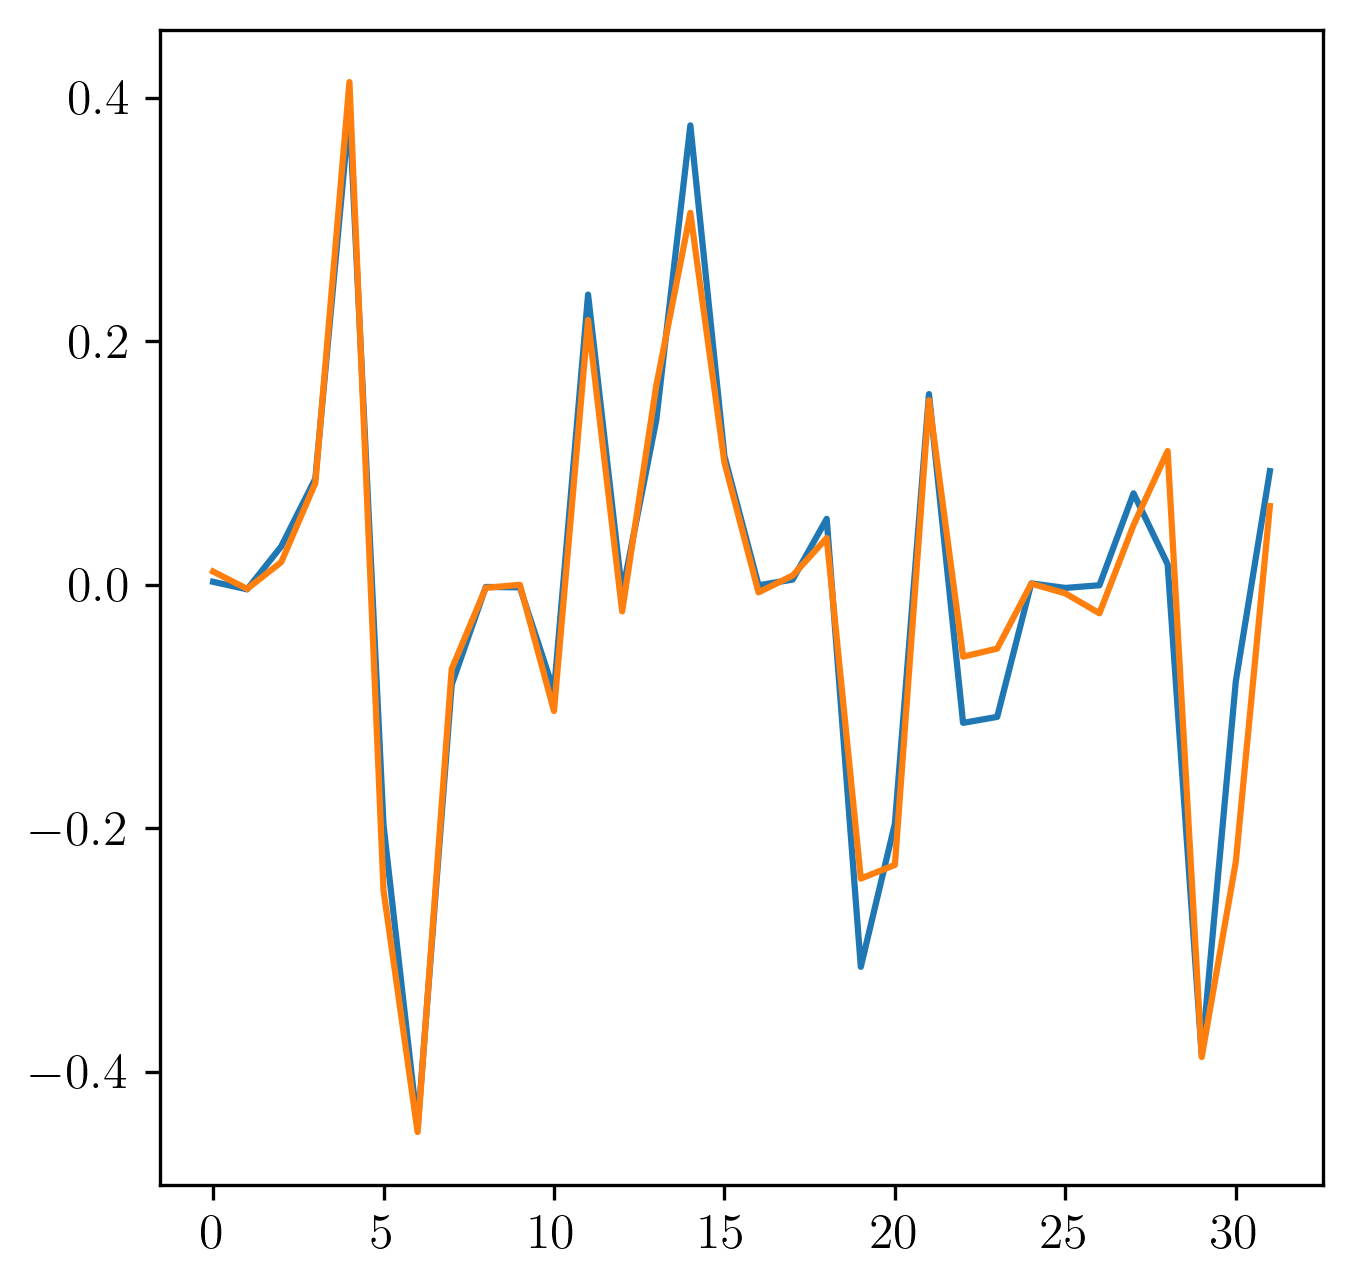

In [12]:
i = 4
plt.plot(e_vecs[:,i])
plt.plot(sv2s[i] * np.sign(sv2s[i] * e_vecs[:,i]))

In [13]:
sv1s_new = []
sv2s_new = []
for i in range(11):
    sv1s_new.append(sv1s[i] * np.sign(sv1s[i] * e_vecs[:,i]))
    sv2s_new.append(sv2s[i] * np.sign(sv2s[i] * e_vecs[:,i]))

sv1s_new = np.array(sv1s_new)
sv2s_new = np.array(sv2s_new)

In [14]:
fid1s = []
for i in range(11):
    fid1 = np.abs(np.dot(sv1s_new[i], e_vecs[:,i].conj()))**2
    fid1s.append(fid1)
    print(f'Fidelity VQE 1 state {i}: {fid1}')
print('----')
fid2s = []
for i in range(10):
    fid2 = np.abs(np.dot(sv2s_new[i], e_vecs[:,i].conj()))**2
    fid2s.append(fid2)
    print(f'Fidelity VQE 2 state {i}: {fid2}')

Fidelity VQE 1 state 0: 0.9907501419976684
Fidelity VQE 1 state 1: 0.593519584744506
Fidelity VQE 1 state 2: 0.451110736341728
Fidelity VQE 1 state 3: 0.5229733576846642
Fidelity VQE 1 state 4: 0.39066750272078654
Fidelity VQE 1 state 5: 0.37448509526002866
Fidelity VQE 1 state 6: 0.3335121136195576
Fidelity VQE 1 state 7: 0.3904329626315485
Fidelity VQE 1 state 8: 0.3733045262552357
Fidelity VQE 1 state 9: 0.35354186618290384
Fidelity VQE 1 state 10: 0.24149588336605174
----
Fidelity VQE 2 state 0: 0.9998870506981906
Fidelity VQE 2 state 1: 0.9990698346960075
Fidelity VQE 2 state 2: 0.9980320178606981
Fidelity VQE 2 state 3: 0.941332314607652
Fidelity VQE 2 state 4: 0.9445144945023761
Fidelity VQE 2 state 5: 0.9650043429961782
Fidelity VQE 2 state 6: 0.8250796176604672
Fidelity VQE 2 state 7: 0.6272833662431474
Fidelity VQE 2 state 8: 0.756836336149982
Fidelity VQE 2 state 9: 0.7239614527570349


In [15]:
print(sv2s_new[0].conj().T @ h_dvr @ sv2s_new[0])
print(e_vecs[:, 0].conj().T @ h_dvr @ e_vecs[:, 0])

(-88.18428099279355+0j)
-88.19579901603797


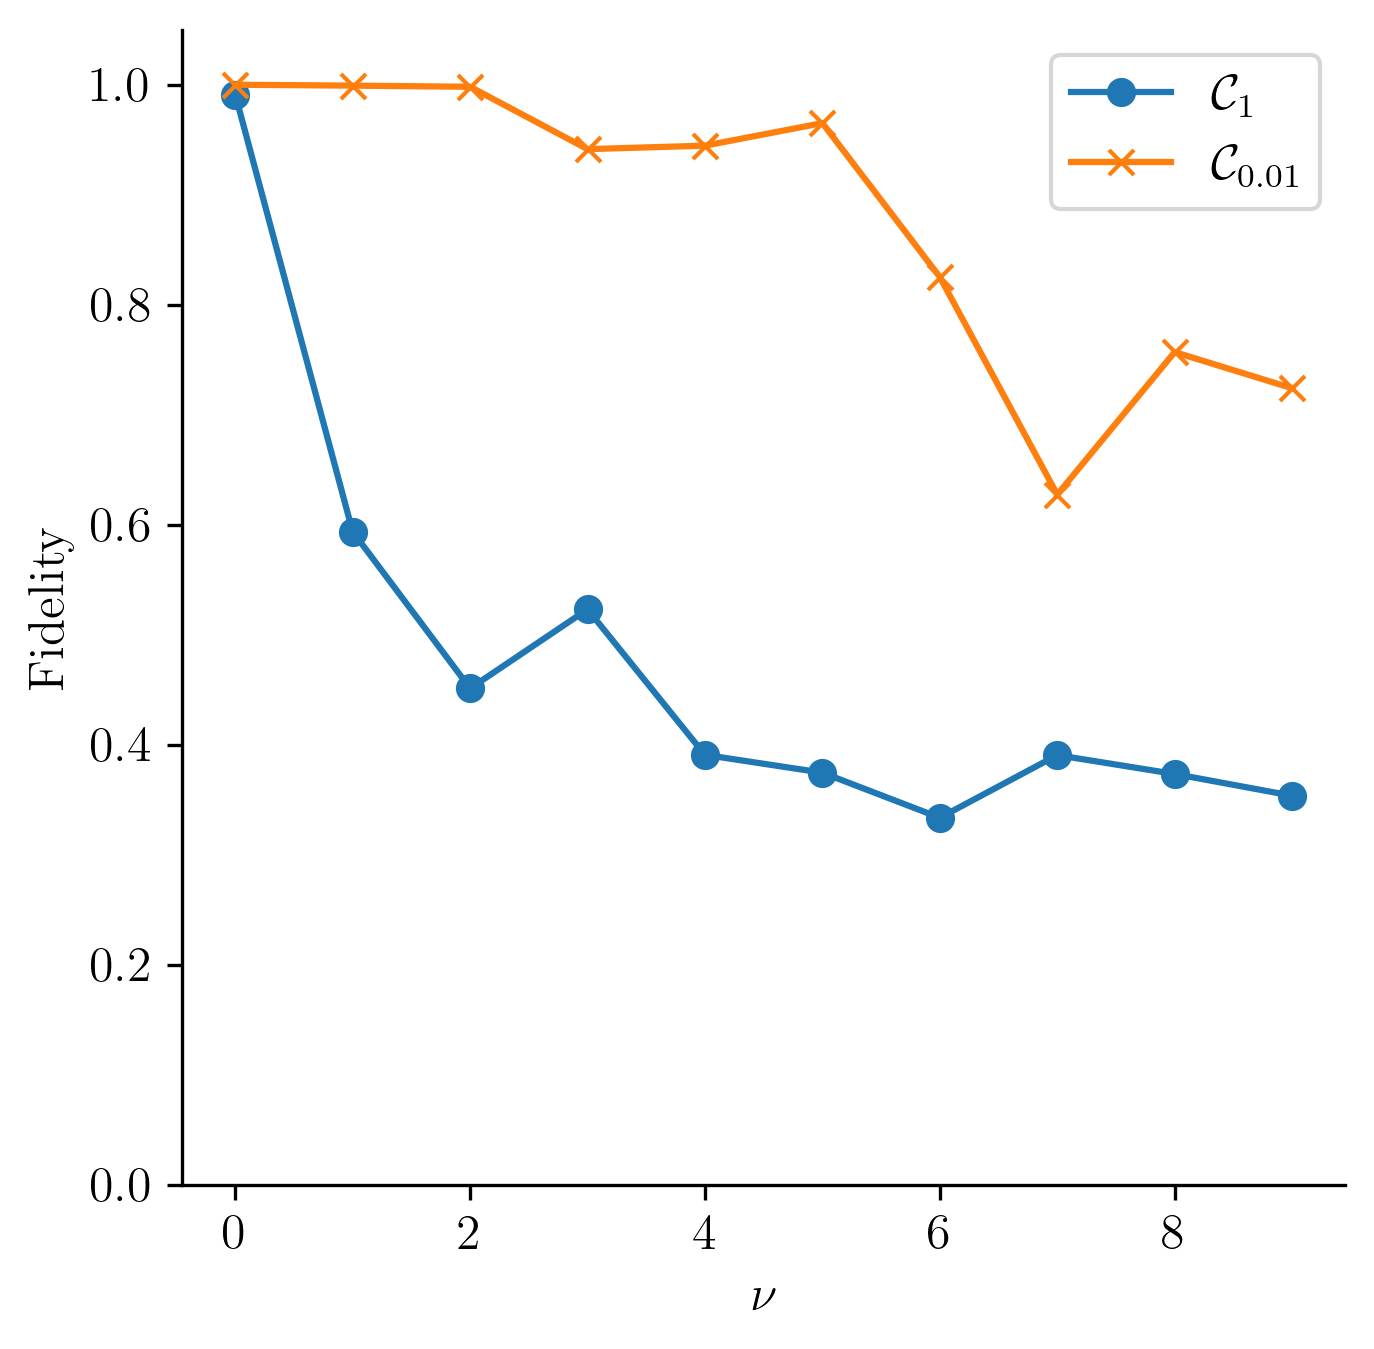

In [19]:
plt.rcParams["figure.figsize"] = (5,5)
plt.rcParams["font.size"] = 12
plt.rcParams["figure.dpi"] = 300

ax = plt.subplot()
ax.plot(fid1s[:-1], 'o-', label='$\\mathcal{C}_1$')
ax.plot(fid2s, 'x-', label='$\\mathcal{C}_{0.01}$')
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)
ax.set_xlabel('$\\nu$')
ax.set_ylabel('Fidelity')
ax.legend()
plt.ylim(0, 1.05)
plt.savefig('figs/mgnh_fidelity.pdf', bbox_inches='tight')